# [실습] 트리 앙상블과 SHAP — 더 강한 모델, 그리고 그 모델 설명하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 5 실습. 해지 요인을 경영진에 어떻게 보고할까?

**필수 머신러닝 · Chapter 5**

| Part | 주제 |
| --- | --- |
| Part 1 | 트리를 모으면 강해진다 |
| Part 2 | 모델이 무엇을 보는가: 피처 중요도와 SHAP |
| Part 3 | SHAP을 읽을 때의 함정 |
| Part 4 | 경영진과 CS팀에 보고하기 |

## 분석 의뢰서

> **의뢰 부서**: 통신사 경영기획팀 (Chapter 1 CS팀 의뢰의 후속)
> **목적**: CS팀의 해지 예측 모델을 경영진 보고에 쓰려 한다. 경영진은 "누가 해지할 것인가"보다 "왜 해지하는가, 무엇을 바꿔야 하는가"를 알고 싶어 한다.
> **제약**: 보고서에 적은 요인을 근거로 요금제나 계약 정책을 바꾸는 결정이 내려질 수 있다. 틀린 요인을 적으면 비용이 든다.
> **질문**: 해지에 영향을 주는 요인은 무엇이며, 그 요인을 바꾸면 해지가 줄어드는가?

## 이 실습의 질문

> **경영진에 보고할 해지 요인 세 가지는 무엇이고, 그중 "바꾸면 해지가 줄어든다"고 말할 수 있는 것은 몇 개인가? 그리고 CS팀 상담원에게 줄 고객별 위험 신호는 어떻게 만들 것인가?**

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |
| **먼저 예상하기** | 결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다 |

## 준비

Chapter 1의 Telco 데이터 `WA_Fn-UseC_-Telco-Customer-Churn.csv`를 이 노트북과 같은 폴더에 두세요. SHAP 라이브러리가 없다면 먼저 설치합니다(`pip install shap`).

이 실습은 앙상블 모델을 교차검증으로 여러 번 학습하므로, 몇몇 셀은 실행에 1분 안팎이 걸립니다.

In [2]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 트리를 모으면 강해진다

## 1-1. 준비

**[제공]** 데이터를 불러와 Chapter 1과 같은 방법(80 : 20, `random_state=42`, `stratify`)으로 나눕니다. 누적 요금(`TotalCharges`)은 Chapter 4에서 확인한 대로 해지 시점에 멈춘 스냅샷 값이라 쓰지 않습니다. 고객 ID(`customerID`)도 피처에서 뺍니다.

| 이름 | 뜻 |
| --- | --- |
| `num_cols` | 숫자 피처 3개: `tenure`(가입 기간), `MonthlyCharges`(월 요금), `SeniorCitizen`(고령 여부 0/1) |
| `cat_cols` | 범주 피처 15개 (계약 유형, 인터넷 종류, 결제 방법 등) |
| `features` | 두 목록을 합친 피처 18개 |

## `stratify` (층화 추출)

```python
train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
```

### 개념
- 데이터를 나눌 때 **train과 test의 클래스 비율을 원본과 똑같이** 맞추는 옵션이다.

### 예시
원본 1000개 중 target=1이 100개(10%)인 경우

| | 전체 | train (800개) | test (200개) |
|---|---|---|---|
| `stratify` 사용 | 10% | 10% (80개) | 10% (20개) |
| `stratify` 미사용 | 10% | 비율이 흔들림 | 비율이 흔들림 |

### 왜 쓰나?
- **불균형 데이터**에서 test에 소수 클래스가 너무 적게 들어가는 것을 막는다.
- train과 test의 분포가 같아야 성능을 공정하게 평가할 수 있다.

### 주의
- **분류 문제**에서 쓴다. 회귀에서 쓰려면 `pd.qcut`으로 구간화한 뒤 넣는다.
- 샘플이 2개 미만인 클래스가 있으면 에러가 난다.

In [3]:
# [제공] 데이터 준비
df = pd.read_csv("실습 데이터/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["target"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])

num_cols = ["tenure", "MonthlyCharges", "SeniorCitizen"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn", "target", "TotalCharges"]]
features = num_cols + cat_cols
y_train, y_test = train_df["target"], test_df["target"]
print(len(train_df), len(test_df), "| 피처 수", len(features), "| 학습용 해지율", round(y_train.mean(), 3))

5634 1409 | 피처 수 18 | 학습용 해지율 0.265


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `make_pipe(모델, scale=True)` | 전처리(숫자 열 스케일링, 범주 열 원핫 인코딩)와 모델을 묶은 파이프라인을 만든다. 트리 계열은 `scale=False` |
| `evaluate_model(이름, 파이프라인)` | 5겹 교차검증 ROC AUC, 학습용 전체로 학습한 뒤의 평가용 ROC AUC·PR AUC, 학습용 ROC AUC를 결과표에 남기고, 학습된 파이프라인을 돌려준다 |
| `compare(이름 A, 모델 A, 이름 B, 모델 B)` | 두 모델을 같은 5겹으로 평가해 fold별 차이를 보여 준다 (Chapter 4) |
| `show_log()` | 결과표를 보여 준다 |

In [4]:
# [제공] 실습 도구
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

def make_pipe(clf, scale=True):
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])

def evaluate_model(name, model):
    s = cross_val_score(model, train_df[features], y_train, cv=cv, scoring="roc_auc")
    model.fit(train_df[features], y_train)
    p_te = model.predict_proba(test_df[features])[:, 1]
    p_tr = model.predict_proba(train_df[features])[:, 1]
    row = {"모델": name, "교차검증 AUC": f"{s.mean():.3f} ± {s.std():.3f}",
           "평가용 AUC": round(roc_auc_score(y_test, p_te), 3),
           "평가용 PR AUC": round(average_precision_score(y_test, p_te), 3),
           "학습용 AUC": round(roc_auc_score(y_train, p_tr), 3)}
    results.append(row)
    print(row)
    return model

def compare(name_a, model_a, name_b, model_b):
    s_a = cross_val_score(model_a, train_df[features], y_train, cv=cv, scoring="roc_auc")
    s_b = cross_val_score(model_b, train_df[features], y_train, cv=cv, scoring="roc_auc")
    diff = s_b - s_a
    print(f"{name_a}: {s_a.round(3)} | 평균 {s_a.mean():.3f} ± {s_a.std():.3f}")
    print(f"{name_b}: {s_b.round(3)} | 평균 {s_b.mean():.3f} ± {s_b.std():.3f}")
    print(f"fold별 차이 (B - A): {diff.round(3)} | 평균 차이 {diff.mean():+.3f}")
    print()

def show_log():
    return pd.DataFrame(results)

## 1-2. 지니 계수 손으로 계산하기

결정트리는 "나눈 뒤 섞임이 가장 많이 줄어드는 질문"을 고릅니다. 섞임은 지니 계수 $G = 2p(1-p)$로 잽니다($p$는 해지 비율).

**[직접 작성]** 학습용 데이터에서 다음을 계산해 출력하세요.

1. 함수 `gini(p)`: $2p(1-p)$를 돌려준다
2. 나누기 전의 지니 계수
3. "월 단위 계약인가"(`Contract == "Month-to-month"`)로 나눈 뒤 두 상자의 고객 수, 해지 비율, 지니 계수
4. 고객 수로 가중 평균한 나눈 뒤의 지니 계수 $G_{\text{split}}$와 감소량 $\Delta G$

<details><summary>힌트</summary>

```python
m = train_df["Contract"] == "Month-to-month"
p_left, p_right = y_train[m].mean(), y_train[~m].mean()
g_split = m.mean() * gini(p_left) + (~m).mean() * gini(p_right)
```
</details>

In [5]:
# 여기에 코드를 작성하세요
def gini(p):
    return 2 * p * (1 - p)

p_all = y_train.mean()
g_before = gini(p_all)
print(f"[나누기 전] 고객 수 {len(y_train)}, 해지 비율 {p_all:.3f}, 지니 {g_before:.4f}")

m = train_df["Contract"] == "Month-to-month"

n_left, n_right = m.sum(), (~m).sum()
p_left, p_right = y_train[m].mean(), y_train[~m].mean()
g_left, g_right = gini(p_left), gini(p_right)

print(f"[월 단위 O] 고객 수 {n_left}, 해지 비율 {p_left:.3f}, 지니 {g_left:.4f}")
print(f"[월 단위 X] 고객 수 {n_right}, 해지 비율 {p_right:.3f}, 지니 {g_right:.4f}")

g_split = m.mean() * g_left + (~m).mean() * g_right
delta_g = g_before - g_split

print(f"G_split = {g_split:.4f}")
print(f"ΔG      = {delta_g:.4f}")

[나누기 전] 고객 수 5634, 해지 비율 0.265, 지니 0.3899
[월 단위 O] 고객 수 3102, 해지 비율 0.427, 지니 0.4895
[월 단위 X] 고객 수 2532, 해지 비율 0.067, 지니 0.1246
G_split = 0.3255
ΔG      = 0.0644


> **[판단]** 월 단위 상자의 지니 계수는 나누기 전보다 커졌습니다. 그런데도 전체로는 섞임이 줄어든 이유는 무엇인가요?
>
> 나의 답: 나눈 뒤의 지니 계수는 두 상자의 지니를 고객 수로 가중 평균한 값이기 때문이다. 월 단위 상자는 해지 비율이 0.5에 가까워져서 지니가 조금 커졌다. 반면 월 단위가 아닌 상자는 해지 비율이 0에 가까워져서 지니가 크게 줄었다. 이 상자도 고객 수가 적지 않기 때문에, 크게 줄어든 효과가 월 단위 상자에서 늘어난 효과보다 컸다. 그래서 가중 평균인 G_split은 나누기 전보다 작아졌다.

## 1-3. 트리 하나의 한계

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다.

> **[판단]** 예상: 깊이 제한 없이 끝까지 자란 트리의 학습용 AUC와 평가용 AUC는 각각 얼마쯤일까요? 깊이 3 트리(평가용 약 0.82)보다 나을까요?
>
> 나의 답: 학습용은 거의 1일 것 같지만 평가용은 깊이 3보다 낮아질 것 같다.

**[직접 작성]** `evaluate_model`로 결정트리 세 개(깊이 3, 깊이 6, 깊이 제한 없음)를 평가하세요. 트리는 스케일링이 필요 없으므로 `make_pipe(..., scale=False)`, `random_state=42`를 씁니다.

<details><summary>힌트</summary>

`evaluate_model("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False))`. 깊이 제한이 없으면 `max_depth=None`(기본값)입니다.
</details>

In [7]:
# 여기에 코드를 작성하세요
evaluate_model("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False))
evaluate_model("트리 깊이 6", make_pipe(DecisionTreeClassifier(max_depth=6, random_state=42), scale=False))
evaluate_model("트리 깊이 제한없음", make_pipe(DecisionTreeClassifier(max_depth=None, random_state=42), scale=False))

{'모델': '트리 깊이 3', '교차검증 AUC': '0.817 ± 0.006', '평가용 AUC': 0.818, '평가용 PR AUC': 0.556, '학습용 AUC': 0.824}
{'모델': '트리 깊이 6', '교차검증 AUC': '0.824 ± 0.011', '평가용 AUC': 0.835, '평가용 PR AUC': 0.617, '학습용 AUC': 0.865}
{'모델': '트리 깊이 제한없음', '교차검증 AUC': '0.658 ± 0.013', '평가용 AUC': 0.669, '평가용 PR AUC': 0.39, '학습용 AUC': 1.0}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['tenure','MonthlyCharges','SeniorCitizen',...,'Contract', 'PaperlessBilling','PaymentMethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

> **[판단]** 예상은 맞았나요? 깊이 제한 없는 트리의 학습용 AUC와 평가용 AUC의 차이를 "편향"과 "분산" 중 무엇으로 설명할 수 있나요? 깊이 3 트리는 어느 쪽의 문제가 더 클까요?
>
> 나의 답: 깊이 제한 없는 트리의 학습용 auc가 1이 나왔다는 것과 평가용은 0.669로 트리 3보다 안 좋아질거라는 예상 둘 다 맞았다. 깊이 제한이 없는 트리는 매우 깊게 학습하게 되어 과적합이 발생했다는 것을 알 수 있다. 학습용과 평가용의 큰 차이는 데이터가 조금만 달라져도 예측이 크게 흔들린다는 뜻이므로 **분산** 문제다. 
> 깊이 3 트리의 경우는 너무 트리가 얕기 때문에 단순해서 데이터의 패턴을 충분히 담지 못했다는 것을 알 수 있다.

## 1-4. 트리들을 서로 다르게: 배깅과 랜덤포레스트

**[제공]** 전처리만 한 학습용·평가용 데이터(`X_tr_t`, `X_te_t`)를 만듭니다. 이 절과 1-6에서 씁니다.

In [8]:
# [제공] 전처리한 데이터 (트리용: 스케일링 없음)
pre_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr_t = pd.DataFrame(pre_tree.fit_transform(train_df[features]), columns=pre_tree.get_feature_names_out())
X_te_t = pd.DataFrame(pre_tree.transform(test_df[features]), columns=pre_tree.get_feature_names_out())
print(X_tr_t.shape, X_te_t.shape)

(5634, 44) (1409, 44)


**[직접 작성]** 부트스트랩 표본 20개를 만들고, 표본마다 깊이 3 트리 두 가지를 학습해 **첫 질문(맨 위 노드)에 쓰인 피처**를 세어 보세요.

- 배깅: `DecisionTreeClassifier(max_depth=3, random_state=b)`
- 피처 후보 제한(랜덤포레스트 방식): `DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b)`

<details><summary>힌트</summary>

```python
rng = np.random.RandomState(42)
idx = rng.randint(0, len(X_tr_t), len(X_tr_t))       # 복원 추출로 고른 행 번호
t = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
root = X_tr_t.columns[t.tree_.feature[0]]             # 첫 질문에 쓰인 피처 이름
```
</details>

In [9]:
# 여기에 코드를 작성하세요
from collections import Counter

rng = np.random.RandomState(42)
roots_bag, roots_rf = [], []

for b in range(20):
    idx = rng.randint(0, len(X_tr_t), len(X_tr_t))
    X_b, y_b = X_tr_t.iloc[idx], y_train.iloc[idx]

    t_bag = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_b, y_b)
    roots_bag.append(X_tr_t.columns[t_bag.tree_.feature[0]])

    t_rf = DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b).fit(X_b, y_b)
    roots_rf.append(X_tr_t.columns[t_rf.tree_.feature[0]])

print("[배깅] 첫 질문 피처")
for name, cnt in Counter(roots_bag).most_common():
    print(f"  {name}: {cnt}")

print("\n[피처 후보 제한] 첫 질문 피처")
for name, cnt in Counter(roots_rf).most_common():
    print(f"  {name}: {cnt}")

[배깅] 첫 질문 피처
  cat__Contract_Month-to-month: 20

[피처 후보 제한] 첫 질문 피처
  num__tenure: 3
  cat__Contract_Month-to-month: 3
  cat__TechSupport_No internet service: 2
  cat__PaymentMethod_Electronic check: 2
  cat__TechSupport_No: 2
  cat__Contract_One year: 1
  cat__DeviceProtection_No internet service: 1
  cat__InternetService_Fiber optic: 1
  num__MonthlyCharges: 1
  cat__Contract_Two year: 1
  cat__PaperlessBilling_No: 1
  cat__StreamingMovies_No internet service: 1
  cat__StreamingTV_No internet service: 1


> **[판단]** 두 방법의 첫 질문은 어떻게 다른가요? 교안 1-3의 식 $\rho\sigma^2 + (1-\rho)\sigma^2/B$와 연결해, 피처 후보를 제한하면 왜 평균의 효과가 커지는지 설명해 보세요.
>
> 나의 답: 배깅은 부트스트랩 표본이 달라도 가장 강한 피처(Contract_Month-to-month)가 거의 매번 첫 질문을 차지했다. 반면 피처 후보를 제한하면 그 피처가 후보에서 빠지는 경우가 생겨 여러 피처가 첫 질문으로 등장했다.
> 식에서 뒤쪽 항 $(1-\rho)\sigma^2/B$는 트리 수 $B$를 늘리면 0에 가까워지지만, 앞쪽 항 $\rho\sigma^2$는 $B$와 상관없이 남는다. 
> 배깅의 트리들은 첫 질문부터 비슷해서 예측도 비슷하므로 트리 간 상관 $\rho$가 크다. 그래서 트리를 많이 만들어도 $\rho\sigma^2$만큼의 분산이 남는다. 피처 후보를 제한하면 트리들이 서로 달라져 $\rho$가 작아지고, 남는 분산 $\rho\sigma^2$도 작아진다. 그래서 평균을 냈을 때 분산이 더 많이 줄어든다.

**[직접 작성]** `evaluate_model`로 랜덤포레스트 두 개를 평가하세요. 둘 다 `n_estimators=300, random_state=42, n_jobs=-1`이고, 하나는 기본값, 하나는 잎에 최소 20명(`min_samples_leaf=20`)입니다.

In [10]:
# 여기에 코드를 작성하세요
evaluate_model(
    "랜덤포레스트(기본값)",
    make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), scale=False),
)

evaluate_model(
    "랜덤포레스트(잎 최소 20명)",
    make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1), scale=False),
)

{'모델': '랜덤포레스트(기본값)', '교차검증 AUC': '0.813 ± 0.012', '평가용 AUC': 0.813, '평가용 PR AUC': 0.596, '학습용 AUC': 1.0}
{'모델': '랜덤포레스트(잎 최소 20명)', '교차검증 AUC': '0.846 ± 0.009', '평가용 AUC': 0.84, '평가용 PR AUC': 0.637, '학습용 AUC': 0.875}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['tenure','MonthlyCharges','SeniorCitizen',...,'Contract', 'PaperlessBilling','PaymentMethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

> **[판단]** 기본값 랜덤포레스트의 학습용 AUC와 평가용 AUC를 보세요. "앙상블이니까 과적합하지 않는다"는 말은 맞나요? 잎의 최소 고객 수를 늘리면 무엇이 달라지나요?
>
> 나의 답: 기본값 랜덤포레스트는 학습용 AUC가 1.0, 평가용 AUC가 0.813으로 차이가 커서 과적합이 일어났다. 따라서 "앙상블이니까 과적합하지 않는다"는 말은 틀렸다.
> 기본값에서는 트리 하나하나가 잎에 1명이 남을 때까지 자라서 학습 데이터를 거의 외운다. 트리를 300개 평균 내면 분산은 줄어든다. 하지만 트리끼리 완전히 독립이 아니므로 식의 $\rho\sigma^2$만큼은 남는다. 그래서 평균을 내도 과적합이 완전히 사라지지는 않는다.
> 잎의 최소 고객 수를 20명으로 늘리면, 트리가 소수의 고객에게만 맞춘 세세한 규칙을 만들 수 없다. 학습용 AUC는 0.875로 내려갔고, 평가용 AUC는 0.84로 학습용과 평가용의 차이가 줄었다. 즉 트리 하나의 분산이 줄어 과적합이 완화되었다.

## 1-5. 부스팅: 트리를 더할수록

**[직접 작성]** 경사 부스팅 모델 `GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42)`를 `X_tr_t`로 학습하고, 트리를 1, 10, 50, 100, 200, 500개 더한 시점의 학습용 AUC와 평가용 AUC를 표로 출력하세요.

<details><summary>힌트</summary>

`staged_predict_proba`는 트리를 하나씩 더할 때마다의 확률을 차례로 돌려줍니다.
```python
for i, (p_tr, p_te) in enumerate(zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1):
    if i in [1, 10, 50, 100, 200, 500]:
        ...  # p_tr[:, 1], p_te[:, 1]로 AUC 계산
```
</details>

In [11]:
# 여기에 코드를 작성하세요
# 1. 경사 부스팅 모델 학습
gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_tr_t, y_train)

# 2. 트리를 하나씩 더할 때마다의 AUC 기록
checkpoints = [1, 10, 50, 100, 200, 500]
rows = []

for i, (p_tr, p_te) in enumerate(
    zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1
):
    if i in checkpoints:
        rows.append({
            "트리 수": i,
            "학습용 AUC": round(roc_auc_score(y_train, p_tr[:, 1]), 3),
            "평가용 AUC": round(roc_auc_score(y_test, p_te[:, 1]), 3),
        })

# 3. 표로 출력
result = pd.DataFrame(rows)
print(result.to_string(index=False))

 트리 수  학습용 AUC  평가용 AUC
    1    0.824    0.818
   10    0.849    0.839
   50    0.868    0.844
  100    0.879    0.843
  200    0.895    0.838
  500    0.930    0.828


> **[판단]** 트리 수를 늘릴 때 학습용과 평가용 AUC는 각각 어떻게 움직이나요? 랜덤포레스트의 트리 수와 무엇이 다른가요? 이 표를 보고 트리 수를 고르면 어떤 문제가 있을까요? (Chapter 4 3-1)
>
> 나의 답: 학습용은 계속 증가하지만 평가용은 증가하다가 어느순간부터 다시 줄어들었다. 랜덤포레스트의 경우 트리 수를 계속 증가해도 각 트리는 독립적이고 평균을 구하여 분산을 줄이는 방식으로 트리가 많아지더라도 과적합이 심해지지 않지만 반면 부스팅은 앞 트리들이 남긴 잔차를 차례로 고쳐 나가므로, 트리가 많아질수록 학습 데이터의 잡음까지 맞추게 되어 과적합할 수 있다. 따라서 부스팅에서는 트리 수가 과적합을 조절하는 하이퍼파라미터가 된다.
> 이 표에서 평가용 AUC가 가장 높은 트리 수를 고르면, 평가용 데이터를 보고 모델을 결정한 셈이 된다. 그러면 평가용 AUC가 실제 성능보다 좋게 나와서, 새로운 데이터에서의 성능을 공정하게 추정할 수 없다. 트리 수는 학습용 데이터에서 떼어 낸 검증용 데이터나 교차 검증으로 골라야 하고, 평가용 데이터는 마지막에 한 번만 사용해야 한다.

## 1-6. 더 강한 모델은 얼마나 강한가

**[직접 작성]** 두 가지를 하세요.

1. `evaluate_model`로 로지스틱 회귀(`make_pipe(LogisticRegression(max_iter=3000))`)와 경사 부스팅 기본값(`GradientBoostingClassifier(random_state=42)`, `scale=False`)을 평가하고, 부스팅 파이프라인을 `gbm_model`에 저장한 뒤 `show_log()`로 결과표를 보세요.
2. `compare`로 "트리 깊이 3 vs 경사 부스팅", "로지스틱 회귀 vs 경사 부스팅"을 비교하세요.

In [12]:
# 여기에 코드를 작성하세요
# 1. 로지스틱 회귀와 경사 부스팅 평가
evaluate_model("로지스틱 회귀", make_pipe(LogisticRegression(max_iter=3000)))

gbm_model = make_pipe(GradientBoostingClassifier(random_state=42), scale=False)
evaluate_model("경사 부스팅", gbm_model)

show_log()

# 2. 두 모델씩 비교
tree3_model = make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False)
logit_model = make_pipe(LogisticRegression(max_iter=3000))

compare("트리 깊이 3", tree3_model, "경사 부스팅", gbm_model)
compare("로지스틱 회귀", logit_model, "경사 부스팅", gbm_model)

{'모델': '로지스틱 회귀', '교차검증 AUC': '0.845 ± 0.012', '평가용 AUC': 0.839, '평가용 PR AUC': 0.63, '학습용 AUC': 0.848}
{'모델': '경사 부스팅', '교차검증 AUC': '0.848 ± 0.011', '평가용 AUC': 0.843, '평가용 PR AUC': 0.654, '학습용 AUC': 0.879}
트리 깊이 3: [0.809 0.814 0.813 0.819 0.827] | 평균 0.817 ± 0.006
경사 부스팅: [0.841 0.833 0.843 0.861 0.86 ] | 평균 0.848 ± 0.011
fold별 차이 (B - A): [0.031 0.019 0.03  0.041 0.033] | 평균 차이 +0.031

로지스틱 회귀: [0.847 0.825 0.841 0.861 0.851] | 평균 0.845 ± 0.012
경사 부스팅: [0.841 0.833 0.843 0.861 0.86 ] | 평균 0.848 ± 0.011
fold별 차이 (B - A): [-0.006  0.008  0.003 -0.001  0.01 ] | 평균 차이 +0.003



> **[판단]** 앙상블은 트리 하나보다 분명히 나은가요? 로지스틱 회귀보다는 나은가요? Chapter 4의 기준(fold별 차이와 편차)으로 판단하세요. 성능만 본다면 어느 모델을 고르겠습니까?
>
> 나의 답:
> - **트리 깊이 3 vs 경사 부스팅**: 평균 차이가 +0.031로, 각 모델의 표준편차 0.006, 0.011보다 크다. 또 모든 fold에서 경사 부스팅이 더 높았다. 따라서 앙상블이 트리 하나보다 분명히 낫다.
> - **로지스틱 회귀 vs 경사 부스팅**: 평균 차이는 0.003인데, 두 모델의 표준편차는 각각 0.012, 0.011로 이 차이보다 훨씬 크다. fold별 차이도 양수와 음수가 섞여 있다. 따라서 경사 부스팅이 로지스틱 회귀보다 분명히 낫다고 말할 수 없다.
> - **선택**: 성능으로는 로지스틱 회귀와 경사 부스팅을 구분할 수 없다. 성능이 같다면 더 단순한 로지스틱 회귀를 고르겠다. 학습이 빠르고, 각 피처가 해지에 어떤 영향을 주는지 계수로 해석하기 쉽기 때문이다.

> **[판단]** 그런데도 이 실습은 Part 2에서 경사 부스팅 모델을 설명에 씁니다. 성능이 비슷한데도 부스팅을 쓸 이유가 있다면 무엇일까요? (교안 1-7, 2-5)
>
> 나의 답: 트리 앙상블은 꺾이는 관계와 피처 사이의 상호작용을 사람이 따로 만들어 주지 않아도 스스로 잡아낸다. 그리고 SHAP(TreeExplainer)으로 그 패턴을 빠르고 정확하게 꺼내 볼 수 있다. SHAP 계산 자체는 로지스틱 회귀에서도 빠르고 정확하므로, 트리 앙상블을 고르는 이유는 계산 속도가 아니라 모델이 담을 수 있는 패턴의 종류 때문이다.
> 예를 들어 가입 기간(tenure)은 초반에는 해지 위험이 매우 높다가 일정 기간이 지나면 급격히 낮아지고 이후에는 거의 변하지 않는 꺾이는 관계를 보일 수 있다. 또 "월 단위 계약이면서 광섬유 인터넷을 쓰는 고객"처럼 두 조건이 겹칠 때 위험이 특히 커지는 상호작용도 있을 수 있다. 로지스틱 회귀는 피처마다 직선 관계만 표현하므로, 이런 패턴을 담으려면 사람이 구간이나 곱 항을 직접 만들어 넣어야 한다.
> 전체 AUC는 비슷하더라도, 설명의 목적은 데이터에 실제로 어떤 패턴이 있는지 보는 것이다. 따라서 이런 패턴을 스스로 담아내는 경사 부스팅이 설명용 모델로 더 알맞다.

---
# Part 2. 모델이 무엇을 보는가

이제부터 `gbm_model`(경사 부스팅 기본값)을 설명합니다.

## 2-1. 피처 중요도 두 가지

**[직접 작성]** 두 가지 중요도의 상위 5개를 출력하세요.

1. **불순도 중요도**: `gbm_model.named_steps["clf"].feature_importances_` (전처리 뒤의 열 이름은 `gbm_model.named_steps["pre"].get_feature_names_out()`)
2. **순열 중요도**: `permutation_importance(gbm_model, test_df[features], y_test, scoring="roc_auc", n_repeats=10, random_state=42)` (원래 피처 18개 기준)

<details><summary>힌트</summary>

결과를 `pd.Series(값, index=이름).sort_values(ascending=False).head(5)`로 정리하면 보기 쉽습니다. 순열 중요도의 값은 `.importances_mean`입니다.
</details>

In [13]:
# 여기에 코드를 작성하세요

imp_names = gbm_model.named_steps["pre"].get_feature_names_out()
imp_values = gbm_model.named_steps["clf"].feature_importances_

impurity_imp = pd.Series(imp_values, index=imp_names).sort_values(ascending=False)

print("[불순도 중요도] 상위 5개")
print(impurity_imp.head(5).round(3))

perm = permutation_importance(gbm_model,
                              test_df[features], y_test,
                              scoring="roc_auc", n_repeats=10, random_state=42,)

perm_imp = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)

print("\n[순열 중요도] 상위 5개")
print(perm_imp.head(5).round(3))

[불순도 중요도] 상위 5개
cat__Contract_Month-to-month        0.386
num__tenure                         0.182
num__MonthlyCharges                 0.101
cat__InternetService_Fiber optic    0.090
cat__OnlineSecurity_No              0.069
dtype: float64

[순열 중요도] 상위 5개
Contract           0.076
tenure             0.072
InternetService    0.009
MonthlyCharges     0.007
OnlineSecurity     0.006
dtype: float64


> **[판단]** 두 중요도의 순위는 어떻게 다른가요? 두 중요도로는 답할 수 없는 질문을 두 가지 적어 보세요. (예: 가입 기간이 길면 해지 확률이 오르나, 내리나?)
>
> 나의 답: 불순도 중요도는 Contract_Month-to-month, tenure, MonthlyCharges, InternetService_Fiber optic, OnlineSecurity_No 순이고, 순열 중요도는 Contract, tenure, InternetService, MonthlyCharges, OnlineSecurity 순이다.
> 상위 피처의 구성은 비슷하지만 두 가지가 다르다. 첫째, 불순도 중요도는 원-핫 인코딩 뒤의 열 기준이라 Contract_Month-to-month처럼 범주별로 나뉘어 나오고, 순열 중요도는 원래 피처 단위로 나온다. 둘째, 숫자 피처인 MonthlyCharges가 불순도 중요도에서는 3위인데 순열 중요도에서는 4위로 내려갔다. 불순도 중요도가 나눌 지점이 많은 숫자 피처를 과대평가하는 경향과 맞는 결과다.
> 두 중요도는 영향의 크기만 알려 주므로 다음 질문에는 답할 수 없다.
> 1. 월 요금이 오를수록 해지 위험이 일정하게 늘까, 아니면 특정 금액부터 급격히 늘까? (관계의 모양)
> 2. 특정 고객 한 명은 왜 해지할 것으로 예측되었을까? (개별 예측의 이유)

## 피처 중요도 두 가지

### 1. 불순도 중요도 (Impurity Importance)
- **뜻**: 트리가 그 피처로 질문해서 섞임(지니)을 얼마나 줄였는지 모두 더한 값
- **비유**: 선수의 경기 기록 보기 (공을 얼마나 잡고 골에 기여했나)
- **계산 시점**: 학습할 때 (`feature_importances_`)
- **단위**: 원-핫 인코딩 뒤의 열
- **약점**: 나눌 지점이 많은 숫자 피처를 과대평가하기 쉬움

```python
names = gbm_model.named_steps["pre"].get_feature_names_out()
vals = gbm_model.named_steps["clf"].feature_importances_
pd.Series(vals, index=names).sort_values(ascending=False).head(5)
```

### 2. 순열 중요도 (Permutation Importance)
- **뜻**: 한 피처의 값을 무작위로 섞었을 때 성능(AUC)이 얼마나 떨어지는지
- **비유**: 그 선수를 빼고 경기해 보기
- **계산 시점**: 학습 후, 평가용 데이터로
- **단위**: 원래 피처 (파이프라인째 넣으면)
- **약점**: 비슷한 피처가 있으면 서로 메꿔 줘서 둘 다 작게 나옴

```python
perm = permutation_importance(gbm_model, test_df[features], y_test,
                              scoring="roc_auc", n_repeats=10, random_state=42)
pd.Series(perm.importances_mean, index=features).sort_values(ascending=False).head(5)
```

### 한눈에 비교

| | 불순도 중요도 | 순열 중요도 |
|---|---|---|
| 질문 | 질문에 얼마나 썼나? | 없으면 얼마나 손해인가? |
| 시점 | 학습 중 | 학습 후 |
| 데이터 | 학습용 | 평가용 |
| 약점 | 숫자 피처 과대평가 | 비슷한 피처끼리 중요도 나눠 가짐 |

> 두 결과의 순위가 다를 수 있다. 하나만 믿지 말고 함께 비교한다.

## 2-2. SHAP 값 계산하고 가산성 확인하기

**[직접 작성]**

1. 평가용 데이터를 `gbm_model`의 전처리로 바꿔 `X_test_t`(열 이름이 붙은 DataFrame)를 만드세요.
2. `shap.TreeExplainer`로 `shap_values`(고객 수 × 피처 수)와 `base_value`(기준값)를 계산하세요.
3. 평가용 첫 고객에서 "기준값 + 기여도 합"과 모델의 로그 오즈 출력(`decision_function`)이 같은지 확인하세요.

<details><summary>힌트</summary>

```python
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0])
```
</details>

In [14]:
# 여기에 코드를 작성하세요

# 1. 평가용 데이터를 전처리해서 X_test_t 만들기
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())
print("X_test_t 크기:", X_test_t.shape)

# 2. SHAP 값과 기준값 계산
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0])
print("shap_values 크기:", shap_values.shape)
print("기준값(base_value):", round(base_value, 4))

# 3. 첫 고객에서 가산성 확인
shap_sum = base_value + shap_values[0].sum()
model_out = gbm.decision_function(X_test_t.iloc[[0]].values)[0]

print(f"기준값 + 기여도 합 = {shap_sum:.6f}")
print(f"모델 로그 오즈 출력 = {model_out:.6f}")
print("같은가?", np.isclose(shap_sum, model_out))

X_test_t 크기: (1409, 44)
shap_values 크기: (1409, 44)
기준값(base_value): -1.5942
기준값 + 기여도 합 = -3.938199
모델 로그 오즈 출력 = -3.938199
같은가? True


> **[판단]** 기준값을 확률로 바꾸면 얼마인가요? ($p = 1/(1 + e^{-z})$) 학습용 해지율(약 0.265)과 같나요? 다르다면 왜 다를까요? (교안 3-2)
>
> 나의 답: 기준값을 확률로 바꾸면 약 0.169로, 학습용 해지율 0.265보다 낮다.
> 기준값은 고객들의 로그 오즈를 평균한 것이고, 해지율은 고객들의 확률을 평균한 것이기 때문이다. 로그 오즈를 확률로 바꾸는 시그모이드는 S자 곡선이라 "평균한 뒤 확률로 바꾼 값"과 "확률로 바꾼 뒤 평균한 값"이 다르다.
> 이 데이터에는 해지 가능성이 매우 낮은 고객이 많은데, 이들은 로그 오즈가 큰 음수라서 로그 오즈의 평균을 크게 끌어내린다. 그래서 기준값을 확률로 바꾸면 실제 해지율보다 낮게 나온다.

## 2-3. 전체 그림: bar와 beeswarm

**[직접 작성]** 피처별 기여도 **절댓값의 평균**을 계산해 상위 8개를 출력하고, `shap.summary_plot(shap_values, X_test_t, max_display=10)`로 beeswarm 그래프를 그리세요.

[SHAP 절댓값 평균] 상위 8개
cat__Contract_Month-to-month           0.639
num__tenure                            0.506
cat__OnlineSecurity_No                 0.242
num__MonthlyCharges                    0.226
cat__TechSupport_No                    0.207
cat__InternetService_Fiber optic       0.199
cat__Contract_Two year                 0.169
cat__PaymentMethod_Electronic check    0.168
dtype: float64


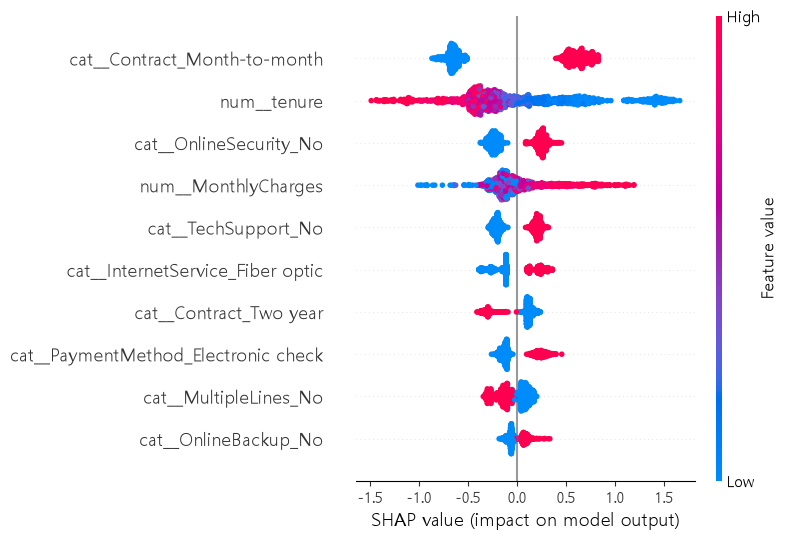

In [15]:
# 여기에 코드를 작성하세요
# 1. 피처별 기여도 절댓값의 평균 (상위 8개)
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test_t.columns)
mean_abs_shap = mean_abs_shap.sort_values(ascending=False)

print("[SHAP 절댓값 평균] 상위 8개")
print(mean_abs_shap.head(8).round(3))

# 2. beeswarm 그래프
shap.summary_plot(shap_values, X_test_t, max_display=10)

> **[판단]** beeswarm 그래프에서 월 단위 계약(`cat__Contract_Month-to-month`)과 가입 기간(`num__tenure`)의 점은 각각 어느 쪽에 모여 있나요? 색(빨강 = 값이 큼)과 함께 읽어, "이 값이 크면 모델은 해지 확률을 올리는가, 내리는가"를 두 피처에 대해 적으세요.
>
> 나의 답: 
> - **월 단위 계약**: 점들이 두 덩어리로 나뉜다. 파란 점(값 0, 월 단위 계약이 아님)은 약 −0.6에, 빨간 점(값 1, 월 단위 계약임)은 약 +0.6 근처에 모여 있다. 따라서 **월 단위 계약이면 모델은 해지 확률을 올린다.**
> - **가입 기간**: 점들이 넓게 퍼져 있다. 파란 점(가입 기간이 짧음)은 오른쪽(최대 약 +1.7)에, 빨간 점(가입 기간이 긺)은 왼쪽(최대 약 −1.5)에 모여 있다. 따라서 **가입 기간이 길수록 모델은 해지 확률을 내린다.**
> - 월 단위 계약은 0/1 피처라 영향이 두 값으로 뚜렷하게 나뉘지만, 가입 기간은 숫자 피처라 고객마다 영향의 크기가 다양하게 퍼져 있다.

## 2-4. 어디서 꺾이는가: dependence

**[직접 작성]** 가입 기간과 월 요금의 기여도를 구간별로 평균해 표로 출력하세요.

- 가입 기간 구간: `[0, 6, 12, 24, 48, 72]` (개월)
- 월 요금 구간: `[0, 40, 70, 90, 120]` (달러)

<details><summary>힌트</summary>

```python
tenure_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__tenure")])
tenure_bin = pd.cut(X_test_t["num__tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
tenure_shap.groupby(tenure_bin.values, observed=True).mean()
```
</details>

In [16]:
# 여기에 코드를 작성하세요
def shap_by_bin(col, bins):
    """한 피처의 SHAP 값을 구간별로 평균 낸 표를 돌려준다."""
    col_idx = list(X_test_t.columns).index(col)       # 그 피처가 몇 번째 열인지
    shap_col = pd.Series(shap_values[:, col_idx])      # 그 열의 SHAP 값 (고객 전원)
    bin_col = pd.cut(X_test_t[col], bins, include_lowest=True)  # 피처 값을 구간으로 나누기

    return shap_col.groupby(bin_col.values, observed=True).agg(["mean", "count"]).rename(
        columns={"mean": "평균 기여도", "count": "고객 수"}
    ).round(3)

print("[가입 기간(개월)별 평균 기여도]")
print(shap_by_bin("num__tenure", [0, 6, 12, 24, 48, 72]))

print("\n[월 요금(달러)별 평균 기여도]")
print(shap_by_bin("num__MonthlyCharges", [0, 40, 70, 90, 120]))

[가입 기간(개월)별 평균 기여도]
               평균 기여도  고객 수
(-0.001, 6.0]   0.950   311
(6.0, 12.0]     0.326   138
(12.0, 24.0]   -0.026   206
(24.0, 48.0]   -0.283   304
(48.0, 72.0]   -0.579   450

[월 요금(달러)별 평균 기여도]
                평균 기여도  고객 수
(-0.001, 40.0]  -0.164   372
(40.0, 70.0]    -0.143   339
(70.0, 90.0]    -0.049   365
(90.0, 120.0]    0.459   333


> **[판단]** 가입 기간의 기여도는 어느 구간에서 가장 크고, 어디쯤에서 0을 지나나요? 월 요금은 "높을수록 해지"라고 말할 수 있나요, 아니면 특정 금액 위에서만 그런가요? 이 결과를 CS팀에 어떤 행동 지침으로 전하겠습니까?
>
> 나의 답: 
> - **가입 기간**: 기여도는 0~6개월 구간에서 +0.950으로 가장 크고, 12~24개월 구간(−0.026)에서 0을 지난다. 즉 가입 1~2년 무렵부터는 평균보다 해지 위험이 낮게 예측된다. 특히 6~12개월 구간에서 기여도가 0.62나 떨어져, 위험이 가장 빠르게 줄어드는 시기는 가입 첫 1년이다.
> - **월 요금**: "높을수록 해지"라고 말할 수 없다. 90달러까지는 기여도가 −0.16에서 −0.05로 거의 평평하고 모두 음수다. 90달러를 넘는 구간에서만 +0.459로 크게 뛴다. 따라서 월 요금은 90달러 이상에서만 해지 위험을 올린다.
> - **CS팀 행동 지침**:
>   1. 가입 후 첫 6개월 고객을 가장 우선적으로 관리한다. 위험이 가장 크고 빠르게 변하는 시기이므로 첫 1년 안에 집중적으로 연락하고 혜택을 안내한다.
>   2. 월 요금이 90달러 이상인 고객에게는 요금제가 사용 패턴에 맞는지 점검하고 상담을 제안한다.
>   3. 두 조건에 모두 해당하는 고객(가입 6개월 이내 + 월 90달러 이상)을 최우선 관리 대상으로 삼는다.
>   단, 이 결과는 모델이 찾은 연관성이지 인과관계가 아니다. 요금을 낮추면 해지가 실제로 줄어드는지는 실험으로 확인해야 한다.

## 2-5. 고객 한 명: waterfall

**[직접 작성]** 평가용 고객 중 모델이 해지 확률을 **가장 높게** 매긴 고객을 찾아, 그 고객의 해지 확률과 가입 기간·계약·월 요금을 출력하고, waterfall 그래프를 그리세요.

<details><summary>힌트</summary>

```python
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
shap.plots.waterfall(shap.Explanation(values=shap_values[i], base_values=base_value,
                                      data=X_test_t.iloc[i], feature_names=list(X_test_t.columns)))
```
</details>

평가용 데이터의 1090번째 고객
해지 확률 : 0.917
가입 기간 : 1개월
계약 형태 : Month-to-month
월 요금   : 95.1달러
실제 해지 : Yes


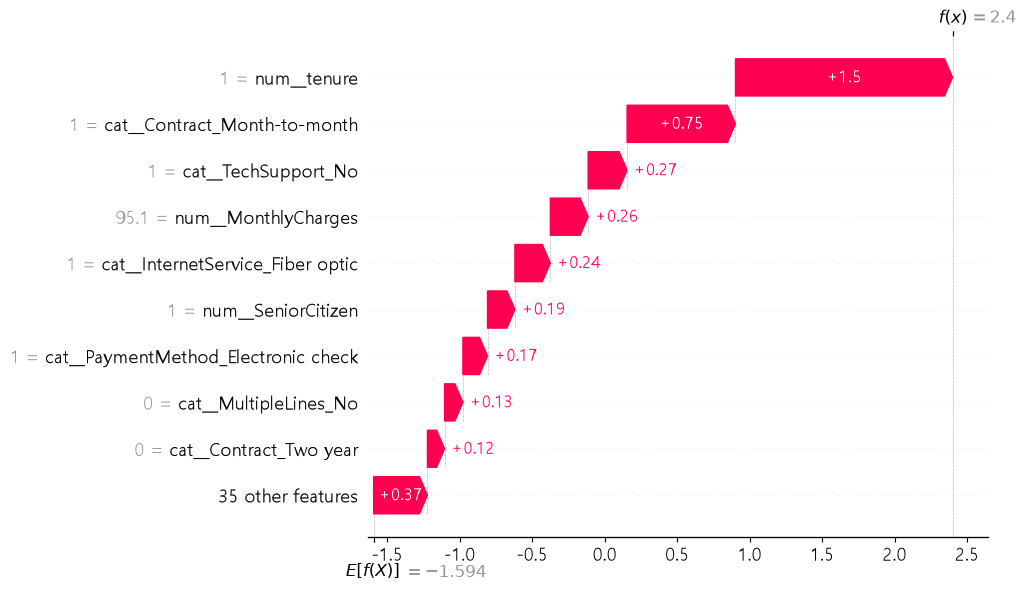

In [17]:
# 여기에 코드를 작성하세요
# 1. 해지 확률이 가장 높은 고객 찾기
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))

# 2. 그 고객의 정보 출력
customer = test_df.iloc[i]
print(f"평가용 데이터의 {i}번째 고객")
print(f"해지 확률 : {prob[i]:.3f}")
print(f"가입 기간 : {customer['tenure']}개월")
print(f"계약 형태 : {customer['Contract']}")
print(f"월 요금   : {customer['MonthlyCharges']}달러")
print(f"실제 해지 : {customer['Churn']}")

# 3. waterfall 그래프
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[i],
        base_values=base_value,
        data=X_test_t.iloc[i].values,
        feature_names=list(X_test_t.columns),
    )
)

> **[판단]** 이 고객에게 전화할 CS팀 상담원에게, 이 그래프를 한 문장으로 바꿔 전해 보세요. 그 문장에 "이것을 바꾸면 해지하지 않는다"는 뜻이 들어가지 않도록 주의하세요.
>
> 나의 답: 이 고객은 가입한 지 1개월 된 월 단위 계약 고객으로, 기술 지원 미가입·월 95달러의 광섬유 요금제 등 해지한 고객들에게서 자주 보이는 특징을 여러 개 함께 갖고 있어 모델이 해지 확률을 약 92%로 가장 높게 예측한 고객입니다.

---
# Part 3. SHAP을 읽을 때의 함정

## 3-1. 상관 피처가 기여도를 나눠 가진다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 월 요금과 광케이블 인터넷은 정보가 많이 겹치는 피처입니다(광케이블 요금이 비쌈).

> **[판단]** 예상: 월 요금을 모델에서 빼고 다시 학습하면, 광케이블 인터넷(`cat__InternetService_Fiber optic`)의 기여도 절댓값 평균은 지금(2-3)보다 커질까요, 작아질까요, 그대로일까요?
>
> 나의 답: 지금보다 훨씬 커질 것이다.

**[직접 작성]** 다음을 계산해 출력하세요.

1. 평가용 데이터에서 월 요금과 "광케이블 여부(0/1)"의 상관계수
2. 현재 모델에서 두 피처의 기여도 절댓값 평균, 그리고 고객마다 두 기여도를 **더한 뒤** 절댓값의 평균
3. 월 요금을 뺀 피처로 경사 부스팅을 다시 학습했을 때, 광케이블의 기여도 절댓값 평균과 평가용 AUC

<details><summary>힌트</summary>

3번은 `num_cols`에서 월 요금을 뺀 전처리를 새로 만들어야 합니다. 이 셀 안에서 `ColumnTransformer`를 직접 만들고, `TreeExplainer`도 새 모델로 다시 만듭니다.
</details>

In [18]:
# 여기에 코드를 작성하세요
mc_col = "num__MonthlyCharges"
fiber_col = "cat__InternetService_Fiber optic"

# 1. 월 요금과 광케이블 여부의 상관계수 (평가용 데이터)
fiber = (test_df["InternetService"] == "Fiber optic").astype(int)
corr = test_df["MonthlyCharges"].corr(fiber)
print(f"[1] 월 요금 vs 광케이블 상관계수: {corr:.3f}")

# 2. 현재 모델에서 두 피처의 기여도
cols = list(X_test_t.columns)
shap_mc = shap_values[:, cols.index(mc_col)]
shap_fiber = shap_values[:, cols.index(fiber_col)]

print("\n[2] 현재 모델 (월 요금 포함)")
print(f"  월 요금 기여도 |평균|      : {np.abs(shap_mc).mean():.3f}")
print(f"  광케이블 기여도 |평균|     : {np.abs(shap_fiber).mean():.3f}")
print(f"  (월 요금 + 광케이블) |평균|: {np.abs(shap_mc + shap_fiber).mean():.3f}")

auc_full = roc_auc_score(y_test, gbm_model.predict_proba(test_df[features])[:, 1])
print(f"  평가용 AUC                 : {auc_full:.3f}")

# 3. 월 요금을 뺀 모델
num_cols_2 = [c for c in num_cols if c != "MonthlyCharges"]
features_2 = num_cols_2 + cat_cols

pre_2 = ColumnTransformer([
    ("num", "passthrough", num_cols_2),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
gbm_model_2 = Pipeline([
    ("pre", pre_2),
    ("clf", GradientBoostingClassifier(random_state=42)),
])
gbm_model_2.fit(train_df[features_2], y_train)

auc_2 = roc_auc_score(y_test, gbm_model_2.predict_proba(test_df[features_2])[:, 1])

X_test_t2 = pd.DataFrame(pre_2.transform(test_df[features_2]), columns=pre_2.get_feature_names_out())
shap_values_2 = shap.TreeExplainer(gbm_model_2.named_steps["clf"]).shap_values(X_test_t2)
shap_fiber_2 = shap_values_2[:, list(X_test_t2.columns).index(fiber_col)]

print("\n[3] 월 요금을 뺀 모델")
print(f"  광케이블 기여도 |평균|: {np.abs(shap_fiber_2).mean():.3f}")
print(f"  평가용 AUC            : {auc_2:.3f}")

[1] 월 요금 vs 광케이블 상관계수: 0.785

[2] 현재 모델 (월 요금 포함)
  월 요금 기여도 |평균|      : 0.226
  광케이블 기여도 |평균|     : 0.199
  (월 요금 + 광케이블) |평균|: 0.385
  평가용 AUC                 : 0.843

[3] 월 요금을 뺀 모델
  광케이블 기여도 |평균|: 0.391
  평가용 AUC            : 0.847


> **[판단]** 예상은 맞았나요? 월 요금을 뺐을 때 광케이블의 기여도와 AUC가 어떻게 변했는지로, "해지 요인은 월 요금인가, 광케이블인가"라는 질문에 SHAP이 답할 수 있는지 판단하세요. 보고서에는 두 피처를 어떻게 적겠습니까?
>
> 나의 답: 예상이 맞았다. 월 요금을 빼자 광케이블의 기여도 절댓값 평균은 0.199에서 0.391로 약 두 배가 되었고, 평가용 AUC는 0.843에서 0.847로 거의 변하지 않았다. 월 요금이 빠져도 성능이 유지된 것은, 광케이블이 월 요금이 담당하던 정보를 대신 맡았기 때문이다. 실제로 원래 모델에서 두 기여도를 더한 뒤의 절댓값 평균(0.385)도 0.391과 비슷하다.
> 따라서 SHAP으로는 "해지 요인이 월 요금인가, 광케이블인가"에 답할 수 없다. 두 피처는 상관이 높아(상관계수 0.785) 비슷한 정보를 담고 있고, SHAP은 모델이 두 피처에 공을 어떻게 나눴는지를 보여 줄 뿐이다. 피처 구성이 바뀌면 나누는 방식도 바뀐다.
> 보고서에는 두 피처를 따로 순위 매기지 않고 "광케이블·고요금 요금제"라는 한 묶음의 위험 신호로 적겠다. 둘 중 무엇이 실제 원인인지는 이 분석으로 구분할 수 없으므로, 비슷한 요금대에서 광케이블 고객과 아닌 고객의 해지율을 비교하거나 요금 조정 실험을 통해 확인해야 한다고 덧붙이겠다.

## 3-2. 단위는 로그 오즈

**[제공]** 같은 기여도(+1.0)가 출발 확률에 따라 확률을 얼마나 바꾸는지 계산합니다.

In [19]:
# [제공] 같은 기여도 +1.0, 다른 확률 변화
sigmoid = lambda z: 1 / (1 + np.exp(-z))
rows = []
for z in [-3, -2, -1, 0, 1]:
    rows.append({"출발 로그 오즈": z, "출발 확률": round(sigmoid(z), 3),
                 "+1.0 뒤의 확률": round(sigmoid(z + 1), 3), "확률 변화 (%p)": round((sigmoid(z + 1) - sigmoid(z)) * 100, 1)})
pd.DataFrame(rows)

,출발 로그 오즈,출발 확률,+1.0 뒤의 확률,확률 변화 (%p)
0,-3,0.047,0.119,7.2
1,-2,0.119,0.269,15.0
2,-1,0.269,0.500,23.1
3,0,0.500,0.731,23.1
4,1,0.731,0.881,15.0


> **[판단]** 어떤 보고서에 "월 단위 계약은 해지 확률을 평균 25%p 올린다"고 적혀 있습니다. 위 표를 근거로 이 문장의 문제를 설명하고, 같은 내용을 정직하게 바꿔 써 보세요.
>
> 나의 답: SHAP 기여도는 로그 오즈 단위이고, 같은 로그 오즈 기여도라도 확률로 바꾸면 고객의 출발 확률에 따라 증가 폭이 달라진다. 따라서 모든 고객에게 같은 "25%p"가 적용되는 것처럼 쓰면 안 된다. 또 "올린다"는 계약 형태를 바꾸면 해지 확률이 그만큼 변한다는 인과의 뜻으로 읽히는데, SHAP은 모델이 예측에 이 피처를 얼마나 반영했는지를 보여 줄 뿐이다.
>
> 정직하게 바꾼 문장: "모델은 월 단위 계약 고객의 해지 로그 오즈를 평균 약 +0.6 높게 예측했다. 이를 확률로 바꾼 증가 폭은 고객마다 달라, 원래 해지 위험이 낮은 고객은 약 4%p, 위험이 중간 정도인 고객은 약 15%p 수준이다. 이는 모델이 찾은 연관성이며, 계약 형태를 바꿨을 때의 효과를 뜻하지는 않는다."

## 3-3. 보고서 문장 판별하기

다음 문장들이 Part 2의 SHAP 결과로 **쓸 수 있는 문장인지** 판단하세요. 쓸 수 없다면 어떤 함정(인과, 로그 오즈 단위, 상관 피처, 틀린 모델)에 걸렸는지 적습니다.

1. "모델은 월 단위 계약, 짧은 가입 기간, 온라인 보안 미가입을 해지 위험의 주요 신호로 사용한다."
2. "월 단위 고객을 2년 계약으로 전환시키면 해지가 줄어든다."
3. "해지 요인은 월 요금이 아니라 인터넷 종류다."
4. "가입 6개월 이내 고객의 해지 위험이 가장 높다."
5. "온라인 보안 서비스를 무료로 제공해 해지가 줄어드는지, 일부 고객에게 무작위로 시범 적용해 확인할 것을 제안한다."

> **[판단]** 1~5번 각각: 쓸 수 있다 / 쓸 수 없다(걸린 함정)
>
> 나의 답: 
> 1. 쓸 수 있다
> 2. 쓸 수 없다 - 인과
> 3. 쓸 수 없다 - 상관 피처
> 4. 쓸 수 있다
> 5. 쓸 수 있다.

---
# Part 4. 경영진과 CS팀에 보고하기

## 4-1. CS팀용 고객별 위험 신호

**[직접 작성]** 평가용 고객 중 해지 확률 상위 10명을 골라, 고객마다 **해지 확률을 가장 많이 올린 피처 3개**(기여도가 큰 양수 순)를 표로 만드세요. 표에는 고객 ID, 해지 확률, 위험 신호 1~3(피처 이름과 기여도)을 넣습니다.

<details><summary>힌트</summary>

```python
top10 = np.argsort(-prob)[:10]
s = pd.Series(shap_values[i], index=X_test_t.columns).sort_values(ascending=False).head(3)
```
</details>

In [20]:
# 여기에 코드를 작성하세요
# 1. 해지 확률 상위 10명의 위치 찾기
prob = gbm_model.predict_proba(test_df[features])[:, 1]
top10 = np.argsort(-prob)[:10]

# 2. 고객마다 위험 신호 3개 뽑기
rows = []
for i in top10:
    s = pd.Series(shap_values[i], index=X_test_t.columns).sort_values(ascending=False).head(3)

    row = {
        "고객 ID": test_df.iloc[i]["customerID"],
        "해지 확률": round(prob[i], 3),
    }
    for k, (name, value) in enumerate(s.items(), start=1):
        row[f"위험 신호 {k}"] = f"{name} ({value:+.2f})"
    rows.append(row)

# 3. 표로 출력
risk_table = pd.DataFrame(rows)
risk_table

,고객 ID,해지 확률,위험 신호 1,위험 신호 2,위험 신호 3
0,5178-LMXOP,0.917,num__tenure (+1.50),cat__Contract_Month-to-month (+0.75),cat__TechSupport_No (+0.27)
1,1069-XAIEM,0.910,num__tenure (+1.49),cat__Contract_Month-to-month (+0.78),cat__TechSupport_No (+0.26)
2,0295-PPHDO,0.910,num__tenure (+1.37),cat__Contract_Month-to-month (+0.75),num__MonthlyCharges (+0.28)
3,6861-XWTWQ,0.899,num__MonthlyCharges (+0.73),cat__Contract_Month-to-month (+0.72),num__tenure (+0.63)
4,0970-ETWGE,0.896,num__tenure (+1.52),cat__Contract_Month-to-month (+0.77),num__MonthlyCharges (+0.32)
5,6230-BSUXY,0.889,num__tenure (+1.59),cat__Contract_Month-to-month (+0.77),cat__TechSupport_No (+0.25)
6,6023-YEBUP,0.887,num__tenure (+0.79),cat__Contract_Month-to-month (+0.71),num__MonthlyCharges (+0.59)
7,1628-BIZYP,0.872,num__tenure (+1.48),cat__Contract_Month-to-month (+0.77),cat__InternetService_Fiber optic (+0.26)
8,0655-RBDUG,0.871,num__MonthlyCharges (+0.79),num__tenure (+0.74),cat__Contract_Month-to-month (+0.72)
9,9248-OJYKK,0.869,num__tenure (+1.46),cat__Contract_Month-to-month (+0.83),cat__TechSupport_No (+0.26)


> **[판단]** 이 표를 상담원이 그대로 쓰기에는 무엇이 불편한가요? (예: 열 이름, 숫자의 단위) 상담원용으로 바꾼다면 위험 신호 열을 어떤 말로 바꾸겠습니까? 한 고객을 골라 예를 들어 보세요.
>
> 나의 답: 피처 이름이 `cat__TechSupport_No`처럼 영어와 코드 형식이라 뜻을 바로 알기 어렵고, 기여도 숫자는 로그 오즈 단위라 얼마나 큰 영향인지 감을 잡을 수 없다. 또 `num__tenure`만 적혀 있고 그 고객의 가입 기간이 실제로 몇 개월인지는 나오지 않는다.
> 상담원용으로는 피처 이름을 쉬운 한국어와 그 고객의 실제 값으로 바꾸고, 기여도 숫자는 강함·보통·약함 같은 등급으로 바꾸겠다. 또 원인처럼 들리지 않도록 "해지 고객에게서 자주 보이는 특징"이라고 표현하겠다.
>
> 예시 (고객 5178-LMXOP, 해지 예상 확률 92%)
> | 위험 신호 | 내용 | 강도 |
> |---|---|---|
> | 1 | 가입한 지 1개월 된 신규 고객 | 강함 |
> | 2 | 약정 없는 월 단위 계약 | 보통 |
> | 3 | 기술 지원 서비스 미가입 | 약함 |
> ※ 해지한 고객들에게서 자주 보이는 특징이며, 해지의 원인을 뜻하지는 않습니다.

## 4-2. 경영진 보고 메모

분석 결과를 경영기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **모델이 해지 위험 신호로 쓰는 요인 세 가지**: 근거 숫자(순위, 방향, 꺾이는 지점)와 함께
2. **"바꾸면 해지가 줄어든다"고 말할 수 있는 요인의 수**: 몇 개이고 왜 그런지
3. **제안**: 무엇을 어떻게 확인할 것인지 (실험)
4. **주의할 점**: 상관 피처, 모델의 한계(성능이 로지스틱 회귀와 비슷함 등)

> **[판단]** 경영진 보고 메모:
>
> 1. 모델이 쓰는 해지 위험 신호 세 가지:
>
> 2. "바꾸면 해지가 줄어든다"고 말할 수 있는 요인:
>
> 3. 제안:
>
> 4. 주의할 점:
>
> 나의 답:
**1. 모델이 해지 위험 신호로 본 요인 세 가지**

과거 고객 데이터로 "누가 해지할지" 예측하는 모델을 만들고, 모델이 어떤 정보를 가장 많이 참고하는지 살펴봤습니다. 영향이 큰 순서는 다음과 같습니다.

| 순위 | 요인 | 모델이 본 패턴 |
|---|---|---|
| 1 | 월 단위 계약 | 약정 없는 월 단위 계약 고객은 위험을 높게, 1·2년 약정 고객은 낮게 봄 |
| 2 | 가입 기간 | 가입 6개월 이내에서 위험이 가장 높고, 첫 1년 동안 가장 빠르게 낮아짐. 가입 1~2년 무렵부터는 평균보다 낮은 위험으로 봄 |
| 3 | 온라인 보안 서비스 미가입 | 미가입 고객은 위험을 높게, 가입 고객은 낮게 봄 |

참고로 월 요금은 90달러까지는 영향이 거의 없다가, **90달러를 넘는 고객에서만** 위험을 크게 높게 봤습니다.

**2. "바꾸면 해지가 줄어든다"고 말할 수 있는 요인: 0개**

이번 분석은 "해지한 고객들에게 어떤 특징이 자주 보였는가"를 찾은 것입니다. "그 특징을 바꾸면 해지가 줄어드는가"는 알려 주지 않습니다.

예를 들어 장기 약정 고객의 해지가 적은 것은, 약정 때문이 아니라 원래 만족도가 높은 고객이 장기 약정을 고르기 때문일 수도 있습니다. 따라서 이 결과만으로는 어떤 요인도 "바꾸면 줄어든다"고 말할 수 없습니다.

**3. 제안: 소규모 시범 운영으로 효과 확인**

가입 6개월 이내의 월 단위 계약 고객 중 일부를 **무작위로** 골라 아래 혜택을 제공하고, 혜택을 받지 않은 고객과 3개월 뒤 해지율을 비교할 것을 제안드립니다.

- A안: 온라인 보안 서비스 3개월 무료 제공
- B안: 1년 약정 전환 시 요금 할인

무작위로 나누면 두 그룹의 다른 조건이 비슷해집니다. 그래서 해지율 차이를 혜택의 효과로 볼 수 있습니다.

**4. 주의할 점**

- **월 요금과 인터넷 종류는 구분이 어렵습니다.** 광케이블 인터넷 고객은 대부분 요금이 높아, 해지 위험이 "비싼 요금" 때문인지 "광케이블 서비스" 때문인지 이번 분석으로는 가를 수 없습니다. 두 가지를 묶어 "광케이블·고요금 고객"으로 보시기를 권합니다.
- **모델의 정확도에는 한계가 있습니다.** 해지 고객과 유지 고객을 한 명씩 뽑았을 때, 해지 고객을 더 위험하다고 맞히는 비율이 약 84%입니다. 또 더 단순한 기존 방식과 정확도가 비슷해서, 복잡한 모델이 특별히 더 정확하다고 보기는 어렵습니다.
- **과거 데이터 기준입니다.** 요금제나 시장 상황이 바뀌면 패턴도 달라질 수 있어, 주기적으로 다시 확인해야 합니다.

---
# 마무리

## 이 Chapter의 판단 포인트

> **SHAP이 큰 요인은 모델이 많이 쓴 요인이지 해지의 원인이 아니다. "요인을 바꾸면 결과가 바뀌는가"는 실험으로 확인한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "SHAP 결과를 보고서에 옮길 때 '요인'을 '원인'으로 바꿔 쓰지 않았는지 확인한다."

> **[판단]** 나의 체크리스트 8번(더 강한 모델을 고를 때):
>
> 나의 답: 변동과 비교하여 확실한 차이가 있는지, 없으면 더 간편하고 쉬운 모델로, 더 강한 모델을 고르고 싶다면 왜 그랬는지

> **[판단]** 나의 체크리스트 9번(모델 설명을 보고할 때):
>
> 나의 답: 요인을 원인으로 오해할만한 말을 쓰지 않았는지, 머신러닝을 모르는 사람이 봐도 이해할 수 있는지, 상관이 높은 피처끼리 기여도를 나눠 갖지 않았는지, 로그 오즈 단위를 고정된 단위로 바꾸진 않았는지

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 6부터는 정답이 없는 데이터를 다루는 비지도학습입니다. 고객을 묶고, 그 묶음을 의심하는 법을 배웁니다.